# Data cleaning

The first chapter said that the largest part of a data scientist's daily work is not modelling but obtaining data, cleaning it and communicating results. This chapter is devoted to the cleaning, to "data scrubbing": spotting outliers, handling missing values, repairing data types, taking text apart with regular expressions, reading dates and times correctly. None of it is mathematically deep, but all of it decides whether the models of the following chapters are any good.

:::{admonition} Principle
Every act of cleaning distorts the data. Removing an outlier, filling in a missing value or normalising a string changes the sample. That is fine as long as three rules hold:

1. **Log it.** Every change is recorded reproducibly in code, ideally with a column that marks which values were changed. Never edit by hand in the CSV file or in Excel.
2. **Look again afterwards.** After every step, plot the distribution again and check whether it still looks plausible.
3. **Measure against the target metric.** Whether you fill missing values in or throw the rows away is not decided by gut feeling but by the metric with which you will later measure the success of the whole pipeline. If you cannot measure it, choose the option that changes the data least.
:::

The example data are daily values from the Düsseldorf weather station, taken from the [open data portal of the German weather service (DWD)](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/historical/), plus the Titanic dataset at the end for the text processing.

## Loading the data and a first look

For each station the DWD supplies a ZIP archive with one data file and several metadata files. Missing values are coded in it as `-999`; that is stated in the description of the file, not in the file itself. Without that piece of information Pandas would read `-999` as a valid temperature, and the mean would be nonsense.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import zipfile, urllib.request, pathlib

base = "https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/historical/"
station = "01078"                                    # Düsseldorf
folder = pathlib.Path(base.replace("https://", ""))  # local copy, same path as on the web

# The file name contains the end date and changes every year, as soon as the DWD appends
# another year. So we search for it: locally first, otherwise in the server's directory listing.
local = sorted(folder.glob(f"tageswerte_KL_{station}_*_hist.zip"))
if local:
    path = local[-1]
else:
    import re
    listing = urllib.request.urlopen(base).read().decode("utf-8")
    filename = re.search(rf"tageswerte_KL_{station}_\d{{8}}_\d{{8}}_hist\.zip", listing).group(0)
    path = folder / filename
    folder.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(base + path.name, path)

with zipfile.ZipFile(path) as archive:
    data_file = [name for name in archive.namelist() if name.startswith("produkt_klima_tag")][0]
    raw = pd.read_csv(archive.open(data_file), sep=";", skipinitialspace=True, na_values=-999)

raw.columns = raw.columns.str.strip()                   # column names have leading spaces
raw = raw.drop(columns="eor")                           # "end of record", no content
print(raw.shape)
raw.tail(3)

(27029, 18)


,STATIONS_ID,MESS_DATUM,QN_3,FX,FM,QN_4,RSK,RSKF,SDK,SHK_TAG,NM,VPM,PM,TMK,UPM,TXK,TNK,TGK
27026,1078,20251229,3.0,5.0,1.4,9.0,0.5,6.0,NaN,0.0,NaN,6.1,1021.1,0.0,97.0,3.8,-5.8,-8.8
27027,1078,20251230,3.0,6.0,1.6,9.0,0.0,0.0,NaN,0.0,1.5,5.5,1023.6,0.2,89.0,4.8,-5.1,-8.1
27028,1078,20251231,3.0,10.5,3.5,9.0,0.2,6.0,NaN,0.0,6.4,5.9,1019.4,0.2,93.0,3.6,-4.9,-8.6


The column names are shorthand codes from the metadata file: `TMK` the daily mean temperature, `TXK` and `TNK` the maximum and the minimum, `RSK` the amount of precipitation in mm, `SDK` the duration of sunshine in hours, `PM` air pressure, `UPM` relative humidity. We keep the columns we need, give them telling names and restrict ourselves to the year 2025. The date stays an integer of the form `YYYYMMDD` for the moment; we deal with that in the section on date and time.

In [2]:
weather = (raw.rename(columns={"MESS_DATUM": "date_raw", "TMK": "temp_mean", "TXK": "temp_max",
                               "TNK": "temp_min", "RSK": "precipitation", "SDK": "sunshine", "PM": "pressure", "UPM": "humidity"})
              .loc[:, ["date_raw", "temp_mean", "temp_max", "temp_min", "precipitation", "sunshine", "pressure", "humidity"]])
weather = weather[(weather["date_raw"] >= 20250101) & (weather["date_raw"] <= 20251231)].reset_index(drop=True)
weather.info()
print("\nMissing values per column:")
print(weather.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   datum_roh     365 non-null    int64  
 1   temp_mittel   365 non-null    float64
 2   temp_max      365 non-null    float64
 3   temp_min      365 non-null    float64
 4   niederschlag  364 non-null    float64
 5   sonne         21 non-null     float64
 6   luftdruck     355 non-null    float64
 7   feuchte       346 non-null    float64
dtypes: float64(7), int64(1)
memory usage: 22.9 KB

Fehlende Werte je Spalte:
datum_roh         0
temp_mittel       0
temp_max          0
temp_min          0
niederschlag      1
sonne           344
luftdruck        10
feuchte          19
dtype: int64


The duration of sunshine is missing on almost every day of 2025; air pressure and humidity have the odd gap. Why, the data file does not say; the answer is in the archive's metadata files, which is the reason they have to be read as well. These are genuine gaps, of the kind that occur in every dataset. To be able to *assess* how gaps are handled, though, we need gaps whose true value we know. So we make a copy and in it deliberately delete a random 10% of the daily mean temperatures. That is rule 3 in action: only with a known truth can we measure which repair is the best.

In [3]:
rng = np.random.default_rng(2025)
truth = weather["temp_mean"].copy()
deleted = rng.random(len(weather)) < 0.10              # mask: which values we "lose"
broken = weather.copy()
broken.loc[deleted, "temp_mean"] = np.nan
broken["temp_mean_missing"] = deleted                  # rule 1: the change is logged as a column
print(f"{deleted.sum()} of {len(weather)} daily means removed")

30 von 365 Tagesmitteln entfernt


## Outliers

An outlier is a value that lies so far away from the others that it is either a measurement error or a rare event that skews the picture. Which of the two it is, the number itself will not tell you; that has to be decided from the context. The first step is always to look. For that we build in two typical errors of the kind that arise when measurements are transcribed: a temperature without its decimal point, and a sign error.

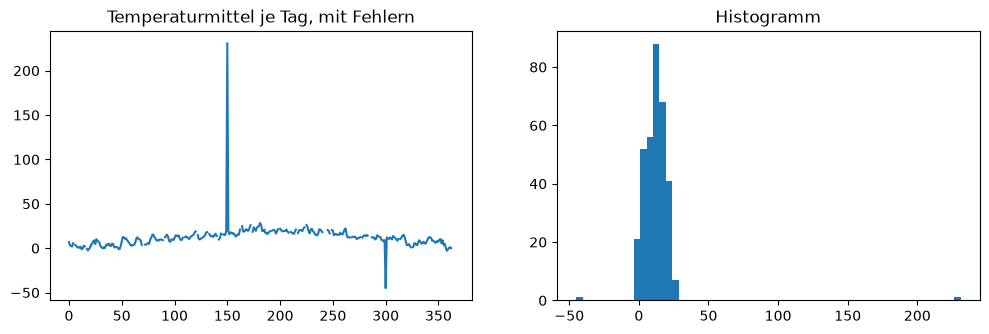

Mittelwert mit Fehlern: 12.21  ohne Fehler: 11.75


In [4]:
faulty = broken.copy()
faulty.loc[150, "temp_mean"] = 231.0     # 23.1 typed without the decimal point
faulty.loc[300, "temp_mean"] = -45.0     # sign and digit transposed

fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
axs[0].plot(faulty["temp_mean"].values); axs[0].set_title("Daily mean temperature, with errors")
axs[1].hist(faulty["temp_mean"].dropna(), bins=60); axs[1].set_title("Histogram")
plt.show()
print("Mean with errors:", faulty["temp_mean"].mean().round(2),
      " without errors:", broken["temp_mean"].mean().round(2))

In the plot both errors are obvious at once; in the mean they hide behind half a degree. Systematically, such values are found with the **z-score**, the deviation from the mean in units of the standard deviation (see [Expected value and variance](expectation-variance.md)). The usual rule of thumb: values with $|z| > 3$ count as outliers. For a normal distribution only one value in 370 lies that far out.

In [5]:
column = faulty["temp_mean"]
z = (column - column.mean()) / column.std(ddof=0)      # z-score by hand; NaN stay NaN, scipy.stats.zscore would do too
outliers = z.abs() > 3                                 # careful: "< 3" would be the mask of the *non*-outliers; NaN gives False
print(faulty.loc[outliers, ["date_raw", "temp_mean"]])


     datum_roh  temp_mittel
150   20250531        231.0
300   20251028        -45.0


Both of the errors we built in are found, and nothing else. That is not a given: the z-score uses the mean and the standard deviation, and both are distorted by the outliers themselves. A single very large error can inflate the standard deviation so much that smaller errors stay below the threshold. More robust is the variant with the median and the interquartile range, the one the boxplot uses.

What do you do with an outlier once you have found it? Not delete the row, because the other columns for that day are fine. Instead set the value to `NaN`, so that it is treated like a missing value in the next section, and keep the mask.

In [6]:
cleaned = faulty.copy()
cleaned["temp_mean_outlier"] = outliers
cleaned.loc[outliers, "temp_mean"] = np.nan
print("Mean after cleaning:", cleaned["temp_mean"].mean().round(2))


Mittelwert nach Bereinigung: 11.73


## Missing values

Pandas has three answers to a missing value: ignore it (most summary measures, `mean` among them, simply leave `NaN` out), discard the row (`dropna`) or insert a substitute value (`fillna`, **imputation**). Discarding is honest but costs data, and not at random: if the duration of sunshine is missing in exactly the last few months, `dropna` throws away exactly those months. Imputation keeps the rows but invents values. The question is which substitute values do least damage. We compare the usual strategies on the deliberately deleted daily mean temperatures, for which we know the truth, with the mean absolute error as the target metric.

In [7]:
column = cleaned["temp_mean"]
month = cleaned["date_raw"] // 100 % 100                     # month number out of YYYYMMDD

strategies = {
    "constant 0":            column.fillna(0),
    "global mean":           column.fillna(column.mean()),
    "global median":         column.fillna(column.median()),
    "monthly mean":          column.fillna(column.groupby(month).transform("mean")),
    "last value (ffill)":    column.ffill(),
    "linear interpolation":  column.interpolate(),
}
result = {name: (replacement[deleted] - truth[deleted]).abs().mean() for name, replacement in strategies.items()}
pd.Series(result, name="MAE in °C").round(2).sort_values()

lineare Interpolation     1.28
letzter Wert (ffill)      1.60
Monatsmittel              2.90
globaler Median           6.11
globaler Mittelwert       6.23
Konstante 0              13.92
Name: MAE in °C, dtype: float64

The order is typical of time series: what knows the neighbours (interpolation, last value) beats what knows only the group (monthly mean), and that beats what knows only the whole (global mean or median). The constant $0$ trails far behind and is nevertheless common in practice, because it is the default setting of some tools. For other data the order can look different: for a column with no temporal ordering `ffill` is pointless, and for skewed distributions with outliers the median is preferable to the mean.

Two details that come up again and again:

* `groupby(...).transform("mean")` computes the mean for each group and writes it back into every row of the group; the result has the same length as the column and can be put straight into `fillna`. If a group is completely empty, its mean is `NaN`, and the gap stays a gap. That is as it should be.
* Older guides write `fillna(method="ffill")`. That no longer exists in Pandas 3; the methods are called `ffill()` and `bfill()`.

And rule 1 once more: after the imputation the column no longer knows which values are real. The mask `temp_mean_missing` from the beginning is the only place where that information survives.

In [8]:
cleaned["temp_mean"] = cleaned["temp_mean"].interpolate()
cleaned["temp_mean_imputed"] = cleaned["temp_mean_missing"] | cleaned["temp_mean_outlier"]
print(cleaned["temp_mean_imputed"].sum(), "values in the column are not measured but inserted")

32 Werte in der Spalte sind nicht gemessen, sondern eingesetzt


## Data types, encoding and categorical values

The first check after loading is `info()`: if a column of numbers has type `object`, a piece of text has crept in – a comma used as the decimal separator, say, a `k.A.` ("no information") or a thousands separator. Such columns are repaired with `pd.to_numeric(..., errors="coerce")`, which turns everything unreadable into `NaN`, and afterwards you count how many values that affected.

Text also has an **encoding**. A file is a sequence of bytes, and only the encoding says which bytes mean which character. The standard is UTF-8; older files from Windows programs are often encoded in Latin-1 or Windows-1252. Assume the wrong encoding and you get either an error message or, worse, silently wrong characters.

In [9]:
word = "Düsseldorf"
utf8 = word.encode("utf-8")
latin1 = word.encode("latin-1")
print("UTF-8:  ", utf8, len(utf8), "bytes")
print("Latin-1:", latin1, len(latin1), "bytes")
print("Latin-1 bytes read as UTF-8:", latin1.decode("utf-8", errors="replace"))
print("UTF-8 bytes read as Latin-1:", utf8.decode("latin-1"))

UTF-8:   b'D\xc3\xbcsseldorf' 11 Bytes
Latin-1: b'D\xfcsseldorf' 10 Bytes
Latin-1-Bytes als UTF-8 gelesen: D�sseldorf
UTF-8-Bytes als Latin-1 gelesen: DÃ¼sseldorf


The second result is the notorious `DÃ¼sseldorf` that turns up in many databases: somebody read UTF-8 as Latin-1 and saved the result. `pd.read_csv` has the parameter `encoding` for this; when in doubt it helps to look at the first bytes of the file with `open(..., "rb")`.

**Categorical values** from free-text fields arrive in many spellings. The route is always the same: normalise first (strip spaces, lower case), then merge the remaining variants with a mapping table, and for typos use the similarity of strings. The standard library brings `difflib` along for that; anyone who needs something more exact takes the edit distance (Levenshtein distance), the number of insertions, deletions and substitutions between two strings.

In [10]:
import difflib

city = pd.Series(["Düsseldorf", "Duesseldorf", "düsseldorf ", "Dusseldorf", "Köln", "Koeln", "Düsseldorf", "Kln"])
normalised = city.str.strip().str.lower().str.replace("ue", "ü").str.replace("oe", "ö")
table = {"dusseldorf": "düsseldorf"}                         # known variants spelled out
normalised = normalised.replace(table)
known = ["düsseldorf", "köln"]
def closest(s):
    matches = difflib.get_close_matches(s, known, n=1, cutoff=0.6)
    return matches[0] if matches else s
result = normalised.map(closest)
print(pd.DataFrame({"raw": city, "normalised": normalised, "assigned": result}))
print("\nDistinct values before:", city.nunique(), " after:", result.nunique())

           roh normalisiert  zugeordnet
0   Düsseldorf   düsseldorf  düsseldorf
1  Duesseldorf   düsseldorf  düsseldorf
2  düsseldorf    düsseldorf  düsseldorf
3   Dusseldorf   düsseldorf  düsseldorf
4         Köln         köln        köln
5        Koeln         köln        köln
6   Düsseldorf   düsseldorf  düsseldorf
7          Kln          kln        köln

Ausprägungen vorher: 7  nachher: 2


Seven spellings become two cities. This too is a distortion: assigning `Kln` to `köln` is a guess, and for a real city called "Kln" it would be wrong. That is why the table of assignments belongs in the log.

How categorical values are then translated into numbers (ordinal and one-hot encoding) is in the table on levels of measurement in the chapter [Descriptive statistics](descriptive-statistics.md).

## Regular expressions

As soon as a column contains text out of which you want to pull something (the title from a name, the domain from a URL, the postcode from an address), you need **regular expressions**. Their reputation for being cryptic strings of characters comes from the way they are written down, not from the thing itself. A regular expression is a compact description of a finite automaton, of the kind you know from the course on formal languages: it runs over the string from left to right and decides at every position whether the character fits. Two rules make working with them bearable:

1. Write regular expressions **on several lines, with comments**. Python allows that with the flag `re.VERBOSE`; spaces and line breaks in the pattern are then ignored, and after a `#` comes a comment.
2. Put whatever you want to pull out in **groups**. `re.search` returns the groups, and Pandas' `str.extract` turns them into columns.

In [11]:
import re

urls = pd.Series(["https://www.hhu.de/studium", "http://opendata.dwd.de/climate_environment/CDC/",
                  "https://voelkel.pages.cs.uni-duesseldorf.de/ds-skript/", "mailto:info@example.org"])
pattern = re.compile(r"""
    ^https?://          # scheme: http or https, then ://
    ([^/]+)             # group 1: everything up to the next slash, that is the host
    (/.*)?$             # group 2 (optional): the path from the slash onwards
""", re.VERBOSE)
print(urls.str.extract(pattern))

                                     0                          1
0                           www.hhu.de                   /studium
1                      opendata.dwd.de  /climate_environment/CDC/
2  voelkel.pages.cs.uni-duesseldorf.de                /ds-skript/
3                                  NaN                        NaN


The last row is `NaN`, because `mailto:` does not fit the pattern. That is wanted: a regular expression says not only *what* it finds but also *that* something fails to conform to the expected format. The number of `NaN`s after an `extract` is therefore a measure of data quality.

The commonest trap is the **greed** of the repetition operators. `.*` takes as many characters as possible and gives back only as much as is needed for the rest of the pattern still to fit. For the automaton that means: it runs to the end and then goes backwards. The "lazy" variant `.*?` takes as little as possible.

In [12]:
html = '<a href="one.html">One</a> and <a href="two.html">Two</a>'
print("greedy:", re.findall(r'<a href="(.*)">', html))     # takes up to the last ">
print("lazy:  ", re.findall(r'<a href="(.*?)">', html))    # takes up to the next ">

gierig: ['eins.html">Eins</a> und <a href="zwei.html']
faul:   ['eins.html', 'zwei.html']


Two constructions are worth the trouble, because they solve problems you can otherwise tinker with for a long time.

The **negative lookahead** `(?!…)` checks that something is *not* in this position, without consuming any characters in the process. So `(?!23)\d\d` matches every two-digit number except `23`. Its counterpart `(?=…)` demands that something does follow.

A **backreference** `\1` stands for whatever group 1 has found, and demands that it stand there once again in exactly the same way. That is how you find doubled words – the classic typo that no spell checker of early word processing ever caught.

In [13]:
print(re.findall(r"(?!23)\d\d", "22 23 24"))   # 23 is missing, 22 and 24 are there

doubled = re.compile(r"\b(\w+)\s+\1\b")
print(doubled.search("She is the the best")[1])        # 'the'
print(doubled.sub(r"\1", "She is the the best"))       # once is enough

['22', '24']
die
Sie ist die beste


Groups are also the reason why a pattern can give back more than "matches / does not match". The pattern

```python
r"^<([a-z]+?)>(.*)</([a-z]+?)>$"
```

takes `"<p>html code</p>"` apart into the three groups `"p"`, `"html code"` and `"p"`. But it also shows the limit straight away: it does not match `'<a href="url">text</a>'`, because the opening tag has an attribute in it. You can extend the pattern, and then comes the next counterexample. The lesson from this is well known and still holds unchanged: **you do not take HTML apart with regular expressions** but with a parser – HTML is not a regular language, and no finite automaton can count nested tags. For a single, known field in a text column, on the other hand, regular expressions are exactly the right tool.

You rarely need more than these building blocks. The following table is the short version, read from the top (binding weakly) to the bottom (binding strongly):

| Building block | Notation | Example | Matches |
|---|---|---|---|
| alternation | `A\|B` | `a\|b` | `a` or `b` |
| concatenation | `AB` | `ab` | `ab` |
| repetition, any number of times | `A*` | `a*` | nothing, `a`, `aa`, … |
| repetition, at least once | `A+` | `a+` | `a`, `aa`, … |
| repetition, optional | `A?` | `a?` | nothing or `a` |
| repetition, counted | `A{n,m}` | `a{2,4}` | `aa`, `aaa`, `aaaa` |
| group | `(A)` | `(ab\|c)` | `ab` or `c`, and remembered as a group |
| any character | `.` | `ab.d` | `abcd`, `ab7d`, … |
| character class | `[…]` | `[abc]`, `[a-z]` | one of the characters named |
| negated character class | `[^…]` | `[^def]` | anything except `d`, `e`, `f` |
| anchor | `^`, `$` | `abc$` | `abc` at the end of the line |

Characters with a special meaning (`.`, `*`, `+`, `?`, `(`, `)`, `[`, `]`, `|`, `^`, `$`, `\`) are written with a backslash in front of them when they are meant literally: `\.` matches a full stop. That is why patterns in Python are always written as a raw string `r"…"` – otherwise every backslash would have to be doubled.

Anyone who works with them regularly should read Friedl's book at some point {cite}`friedl2006`; it explains how the automata really run and why some patterns are slow.

:::{admonition} Example exercise: titles in the Titanic dataset
:class: tip
The column `Name` of the Titanic passenger list has the form `Surname, Title. Forenames`, for instance `Braund, Mr. Owen Harris`. Extract the title into a new column, count the values, merge rare and synonymous titles and compute the survival rate for each title. What does the result say about the order in which people were rescued?
:::

In [14]:
titanic = pd.read_csv("titanic.csv")
titanic["Title"] = titanic["Name"].str.extract(r",\s*([^.]+)\.")    # after the comma up to the first full stop
print(titanic["Title"].value_counts())

Anrede
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64


In [15]:
combine = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs",
           "Dr": "Rank", "Rev": "Rank", "Col": "Rank", "Major": "Rank", "Capt": "Rank",
           "Sir": "Nobility", "Lady": "Nobility", "the Countess": "Nobility", "Don": "Nobility", "Jonkheer": "Nobility"}
titanic["Title"] = titanic["Title"].replace(combine)
titanic.groupby("Title")["Survived"].agg(["mean", "size"]).sort_values("mean", ascending=False)

,mean,size
Anrede,,
Mrs,0.793651,126
Miss,0.702703,185
Adel,0.600000,5
Master,0.575000,40
Rang,0.277778,18
Mr,0.156673,517


:::{admonition} Solution
:class: dropdown
The two hidden cells above contain the code. The pattern `,\s*([^.]+)\.` reads all the characters after the comma and optional spaces up to the first full stop into a group. There are seventeen titles, most of them rare; `Mlle` and `Ms` are variants of `Miss`, `Mme` of `Mrs`, and the professional and noble titles are merged into two groups. The survival rates are then: `Mrs` and `Miss` at around 70 to 80 per cent, `Master` (boys) above 50 per cent, `Mr` below 20 per cent. That is the rule "women and children first", read off a text field. The title is therefore a better feature for predictions than sex alone, because it additionally encodes the age of the boys; this sort of thing is called *feature engineering*.
:::

Regular expressions are not learned by reading. Two sites help with the practice: [regexone.com](https://regexone.com) leads through all the building blocks in fifteen small exercises, and the [regex visualizer](https://27t.github.io/regex-visualizer/) draws the finite automaton belonging to a pattern – for `a(ffe|de)+` you can see at once where the loop sits that the `+` creates.

## Date, time and time zones

Dates are text in one of dozens of formats: `20250115`, `15.01.2025`, `01/15/2025`, `2025-01-15T14:30:00+01:00`, or a number of seconds since 1 January 1970 (the *Unix timestamp*). Pandas reads most of them with `to_datetime`. You should state the format, though, instead of letting it be guessed: with the date `01/02/2025` guessing is a matter of luck, and guessing is slow as well. And you keep the raw date as a column until you are sure the conversion is right.

In [16]:
cleaned["date"] = pd.to_datetime(cleaned["date_raw"], format="%Y%m%d")
print(cleaned[["date_raw", "date"]].head(3))
print("\nType of the new column:", cleaned["date"].dtype)

   datum_roh      datum
0   20250101 2025-01-01
1   20250102 2025-01-02
2   20250103 2025-01-03

Typ der neuen Spalte: datetime64[us]


With a real date type the useful questions become one-liners: day of the week, month, the gap between two days, or aggregating up to months with `resample`. For that we make the date the index.

In [17]:
w = cleaned.set_index("date")
print("Day of the week of the first entry:", w.index[0].day_name())
print("Days between the first and the last entry:", (w.index[-1] - w.index[0]).days)
monthly = w[["temp_mean", "precipitation"]].resample("MS").agg({"temp_mean": "mean", "precipitation": "sum"})
monthly.round(1).head(6)

Wochentag des ersten Eintrags: Wednesday
Tage zwischen erstem und letztem Eintrag: 364


,temp_mittel,niederschlag
datum,,
2025-01-01,3.2,103.6
2025-02-01,4.3,18.6
2025-03-01,8.0,6.2
2025-04-01,12.1,71.0
2025-05-01,14.5,23.8
2025-06-01,19.6,52.4


**Time zones** are the place where most of the mistakes happen. A timestamp without a time zone is ambiguous: `2025-03-30 02:30` never existed in Germany, because that night the clock jumped from 2:00 to 3:00, and `2025-10-26 02:30` existed twice. Pandas therefore distinguishes *naive* timestamps (without a time zone) from *aware* ones (with). `tz_localize` says which time zone a naive timestamp was meant to be in; `tz_convert` converts an aware one into another time zone. Confusing the two shifts all the times by one or two hours, and that is noticed only when sunrise stands in the data at 6 o'clock instead of 7.

In [18]:
times = pd.to_datetime(["2025-01-15 12:00", "2025-07-15 12:00"])    # naive: no time zone
local = times.tz_localize("Europe/Berlin")                            # this is how they were meant
print("local:", list(local))
print("UTC:  ", list(local.tz_convert("UTC")))                        # one hour's difference in winter, two in summer
print("Unix timestamp:", list((local - pd.Timestamp("1970-01-01", tz="UTC")) // pd.Timedelta("1s")))  # seconds since 1970, time-zone-free
try:
    pd.Timestamp("2025-03-30 02:30").tz_localize("Europe/Berlin")
except Exception as error:
    print("Error:", type(error).__name__, "-", error)

lokal: [Timestamp('2025-01-15 12:00:00+0100', tz='Europe/Berlin'), Timestamp('2025-07-15 12:00:00+0200', tz='Europe/Berlin')]
UTC:   [Timestamp('2025-01-15 11:00:00+0000', tz='UTC'), Timestamp('2025-07-15 10:00:00+0000', tz='UTC')]
Unix-Zeitstempel: [1736938800, 1752573600]
Fehler: ValueError - 2025-03-30 02:30:00 is a nonexistent time due to daylight savings time. Try using the 'nonexistent' argument.


The time zone rules, together with all the daylight-saving changes of the past, are in the *tz database* (also called the IANA time zone database), which Python brings along in the module `zoneinfo`; the names such as `Europe/Berlin` come from there. Anyone who stores timestamps stores them in UTC or as Unix timestamps and converts to local time only for display.

## Summary

Besides the measurements, the cleaned DataFrame now carries three columns that are nothing but the log: which values were missing, which were identified as outliers and which have therefore been inserted. Anyone who later trains a model on it can exclude or weight those rows, and anyone who reads the analysis can see what is measurement and what is guesswork.

In [19]:
cleaned[["date", "temp_mean", "temp_mean_missing", "temp_mean_outlier", "temp_mean_imputed"]].iloc[148:153]

,datum,temp_mittel,temp_mittel_fehlt,temp_mittel_ausreisser,temp_mittel_imputiert
148,2025-05-29,14.7,False,False,False
149,2025-05-30,19.6,False,False,False
150,2025-05-31,19.2,False,True,True
151,2025-06-01,18.8,False,False,False
152,2025-06-02,15.7,False,False,False


:::{admonition} Take-home message
Cleaning always distorts. It is permitted if every change stands in the code, a mask records which values are affected, and the choice of method was measured against a target metric. Before any calculation, `info()` and a plot; after the cleaning, another plot.
:::

What comes next: with clean tables we can investigate relationships between columns. The next chapter introduces covariance and correlation for that.